In [1]:
#Importación de librerias
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split


In [5]:
# Cargar
artifacts = joblib.load("../../models/modelo_regresion_multiple.joblib")
type(artifacts)


dict

In [8]:
artifacts["X_test"]

,TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC
46,1.18,53.0,6,0.45,15.98
9,1.09,57.0,5,0.52,17.04
206,1.37,56.5,10,0.41,13.05
139,1.28,52.5,7,0.41,16.02
60,1.19,50.0,8,0.42,12.71
...,...,...,...,...,...
124,1.26,62.0,7,0.49,18.58
197,1.36,79.0,11,0.58,24.25
244,1.44,71.0,10,0.49,22.47
226,1.39,66.5,9,0.48,21.19


In [26]:
#Metricas recuperadas
metrics   = artifacts["metrics"]

print("Métricas recuperadas:")
print(f"r2  : {metrics['r2']:.4f}")
print(f"MAE : {metrics['mae']:.4f}")
print(f"MSE : {metrics['mse']:.4f}")


Métricas recuperadas:
r2  : 0.9856
MAE : 0.9344
MSE : 1.5842


In [27]:
#Recuperar Conjuntos 
X_test    = artifacts["X_test"]
y_test    = artifacts["y_test"]
y_pred    = artifacts["y_pred"]
print(X_test.shape, y_test.shape, y_pred.shape)

(63, 5) (63,) (63,)


In [12]:
model     = artifacts["model"]
type(model)

sklearn.linear_model._base.LinearRegression

In [28]:
#Listar las claves de un diccionario
artifacts.keys()

dict_keys(['model', 'metrics', 'feature_names', 'X_test', 'y_test', 'y_pred'])

In [19]:
b0 = model.intercept_
bx = model.coef_.round(4)
print(f"Modelo de regresion: {b0:.4f} + {bx}")

Modelo de regresion: 14.6584 + [-1.172100e+01  1.308300e+00 -1.043000e-01 -1.680332e+02  1.766800e+00]


Se obtiene la ecuación:

y^i = 14.6583 -11.7210 X1 + 1.3083 X2 -0.1042 X3 - 168.03 X4 + 1.7667 X5

Se observa un mejor ajuste de las predicciones respecto a los valores reales de y.

De momento se asume una mejora del modelo no considerando el cumplimiento de los supuestos de Linealidad.

**Analisis de Residuos**

In [30]:
#Realizamos ahora el calculo del valor de los residuos e= yi -y^i 
#Sobre los valores con lo que fue entrenado el modelo
residuos = y_test - y_pred
residuos.shape
residuos.head(10)

46     0.088715
9      1.585771
206   -1.141044
139   -0.772730
60     0.825793
33     0.673508
297   -0.164067
186   -0.333458
296    1.269533
277    2.922190
Name: PESO (KG), dtype: float64

**1.- Distribución de los valores de los residuos**

Text(0.5, 0, 'Valor residual')

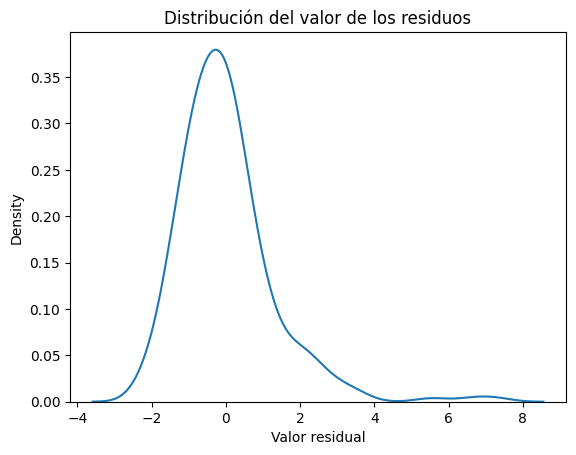

In [ ]:
#Viasualizamos la distribución de los residuos mediante un Kdeplot
sns.kdeplot(residuos)
plt.title("Distribución del valor de los residuos")
plt.xlabel("Valor residual")

Se observa en el Kdeplot que los valores de los residuos se distribuyen alrededor del valor 0, lo que es adecuado para el modelo, sin embargo, tambien presenta una cola de residuos positivos muy alargada (a la derecha), es decir, en algunos casos el modelo subestimó con fuerza.

In [31]:
residuos_df = pd.DataFrame({
    "real": y_test,
    "predicho": y_pred,
    "residuo": residuos
})

residuos_df.head(10)

,real,predicho,residuo
46,22.25,22.161285,0.088715
9,20.25,18.664229,1.585771
206,24.50,25.641044,-1.141044
139,26.25,27.022730,-0.772730
60,18.00,17.174207,0.825793
33,18.30,17.626492,0.673508
297,43.35,43.514067,-0.164067
186,29.10,29.433458,-0.333458
296,42.20,40.930467,1.269533
277,47.50,44.577810,2.922190


En este punto de analisis de la distribución nos interesa encontrar que la media de los valores residuales tenga un valor cercano a CERO.

In [29]:
print("Media:", residuos.mean())
print("Mediana:", residuos.median())
print("Desviación estándar:", residuos.std())
print("Mínimo:", residuos.min())
print("Máximo:", residuos.max())

Media: -1.0231815394945442e-15
Mediana: -0.15195296679811143
Desviación estándar: 1.2978041993311755
Mínimo: -2.303350653390467
Máximo: 7.266388363513883


In [30]:
residuos.describe()

count    2.500000e+02
mean    -1.023182e-15
std      1.297804e+00
min     -2.303351e+00
25%     -7.884877e-01
50%     -1.519530e-01
75%      4.909697e-01
max      7.266388e+00
Name: PESO (KG), dtype: float64

Esta comprobación del valor de la media de los residuos cercana a 0 es una propiedad esperable del ajuste OLS con intercepto.

**2.- Residuos contra Valores predichos**

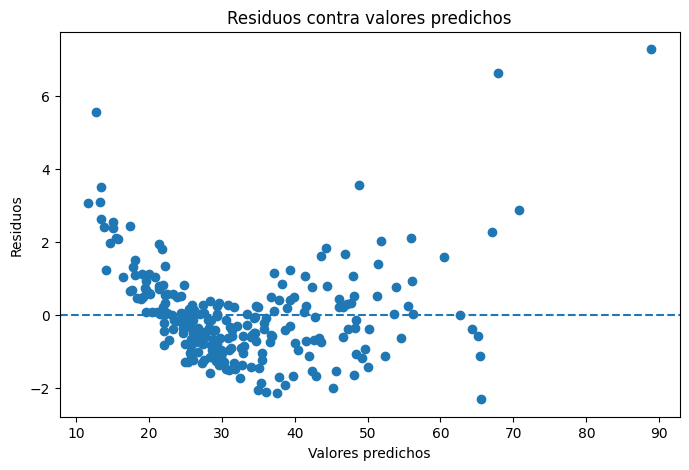

In [36]:
plt.figure(figsize=(8,5))

plt.scatter(y_pred_train, residuos)

plt.axhline(0, linestyle="--")

plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos contra valores predichos")

plt.show()

Desde el kdeplot de la distribución de los residuos se observa que existen residuos positivos muy alejados de la media, sin embargo no es, sino hasta visualizar el scatterplot de los valores predichos contra los residuos que observamos la "forma" o "tendencia" que siguen.

**Los residuos no deberían contener estructura sistemática.**

**3.- Normalidad de los errores**

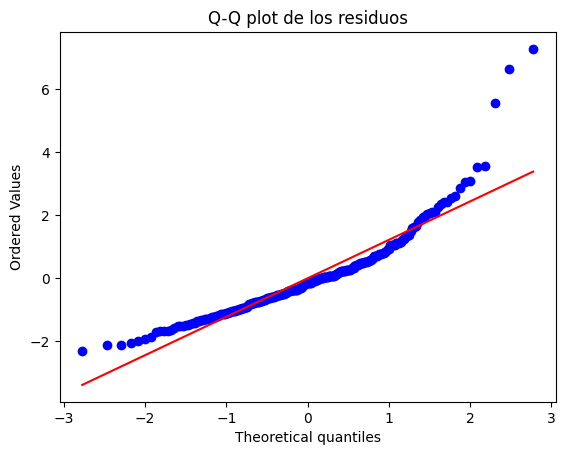

In [38]:
import scipy.stats as stats

stats.probplot(residuos, dist="norm", plot=plt)

plt.title("Q-Q plot de los residuos")
plt.show()